Análise Exploratória dos Dados

Objetivo:
Este notebook tem como objetivo explorar o comportamento da variável nps_score e investigar sua relação com características dos clientes, pedidos, entregas, atendimento e recompra.
A análise será iniciada pela distribuição exploratória do NPS, ainda sem aplicar a classificação utilizada pelo método para detratores, passivos e promotores. Essa abordagem permite compreender a concentração das notas, sua dispersão, possíveis assimetrias e mudanças de comportamento ao longo da escala.
Posteriormente, serão analisadas faixas de NPS e suas relações com os indicadores operacionais e de negócio, buscando identificar fatores associados à satisfação dos clientes e possíveis pontos de ruptura na experiência.

In [110]:
# SETUP
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Pasta para armazenamento dos gráficos gerados na EDA
pasta_figuras = Path("../5.outputs/1.figures")
pasta_figuras.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../1.data/1.raw/desafio_nps_fase_1.csv")

Fase 1 - Análise da distribuição do NPS
Nesta etapa, a variável nps_score será analisada em sua forma original e contínua, sem a aplicação inicial das categorias tradicionais do NPS.

O objetivo é compreender a distribuição das notas, sua dispersão e possíveis concentrações ou padrões ao longo da escala.

In [ ]:

#limites e valores existentes na escala
nps = df["nps_score"]

print(f"Menor nota: {nps.min():.1f}")
print(f"Maior nota: {nps.max():.1f}")
print(f"Quantidade de notas distintas: {nps.nunique()}")

np.sort(nps.unique())

Menor nota: 0.0
Maior nota: 10.0
Quantidade de notas distintas: 101


array([ 0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,
        1.1,  1.2,  1.3,  1.4,  1.5,  1.6,  1.7,  1.8,  1.9,  2. ,  2.1,
        2.2,  2.3,  2.4,  2.5,  2.6,  2.7,  2.8,  2.9,  3. ,  3.1,  3.2,
        3.3,  3.4,  3.5,  3.6,  3.7,  3.8,  3.9,  4. ,  4.1,  4.2,  4.3,
        4.4,  4.5,  4.6,  4.7,  4.8,  4.9,  5. ,  5.1,  5.2,  5.3,  5.4,
        5.5,  5.6,  5.7,  5.8,  5.9,  6. ,  6.1,  6.2,  6.3,  6.4,  6.5,
        6.6,  6.7,  6.8,  6.9,  7. ,  7.1,  7.2,  7.3,  7.4,  7.5,  7.6,
        7.7,  7.8,  7.9,  8. ,  8.1,  8.2,  8.3,  8.4,  8.5,  8.6,  8.7,
        8.8,  8.9,  9. ,  9.1,  9.2,  9.3,  9.4,  9.5,  9.6,  9.7,  9.8,
        9.9, 10. ])

In [11]:
#medidas de posição e dispersão
nps.describe()

count   2500.00
mean       4.38
std        2.51
min        0.00
25%        2.60
50%        4.40
75%        6.10
max       10.00
Name: nps_score, dtype: float64

In [ ]:
#medidas de posição e dispersão
nps.describe()

estatisticas_nps = {
    "média": nps.mean(),
    "mediana": nps.median(),
    "moda": nps.mode().tolist(), #Para definir notas mais frequêntes
    "variância": nps.var(),
    "desvio_padrão": nps.std(),
    "assimetria": nps.skew()  # Para entender concentração da distribuição das notas
}

estatisticas_nps

{'média': np.float64(4.3786),
 'mediana': np.float64(4.4),
 'moda': [0.0],
 'variância': np.float64(6.301250540216087),
 'desvio_padrão': np.float64(2.5102291808151875),
 'assimetria': np.float64(0.11040699190283026)}

In [ ]:

#Frequência das notas
# Cálculo da frequência absoluta e percentual de cada valor do nps_score, permitindo identificar concentrações específicas ao longo da escala.

frequencia_nps = (
    nps.value_counts()
       .sort_index()
       .rename_axis("nps_score")
       .reset_index(name="quantidade")
)

frequencia_nps["percentual"] = (
    frequencia_nps["quantidade"] / len(df) * 100
)
frequencia_nps

,nps_score,quantidade,percentual
0,0.00,158,6.32
1,0.10,8,0.32
2,0.20,14,0.56
3,0.30,10,0.40
4,0.40,14,0.56
...,...,...,...
96,9.60,8,0.32
97,9.70,3,0.12
98,9.80,4,0.16
99,9.90,3,0.12


DIstribuição do NPS - Visual
O objetivo é identificar visualmente concentrações, dispersão, assimetrias e possíveis comportamentos específicos nos extremos da escala.

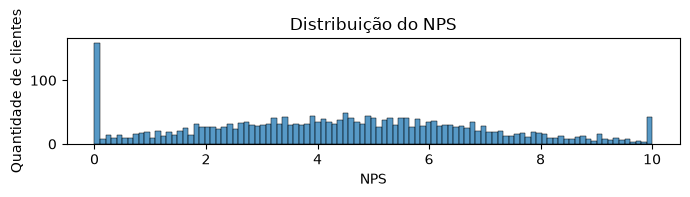

In [111]:
# Histograma NPS - quantidade de clientes por nota
plt.figure(figsize=(7, 2))

sns.histplot(
    data=df,
    x="nps_score",
    bins=101
)

plt.title("Distribuição do NPS")
plt.xlabel("NPS")
plt.ylabel("Quantidade de clientes")

plt.tight_layout()

plt.savefig(
    pasta_figuras / "01_distribuicao_nps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

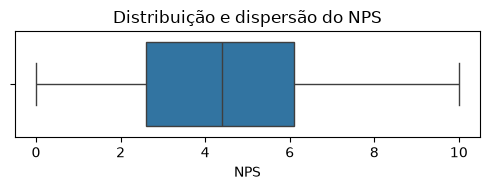

In [113]:
# Boxplot NPS - observar mediana, intervalo interquartil, dispersão e possíveis outliers
plt.figure(figsize=(5, 2))

sns.boxplot(
    data=df,
    x="nps_score"
)

plt.title("Distribuição e dispersão do NPS")
plt.xlabel("NPS")

plt.tight_layout()

plt.savefig(
    pasta_figuras / "02_boxplot_nps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#A distribuição do NPS será comparada entre as regiões para verificar se existem diferenças relevantes no comportamento das notas que não sejam evidentes apenas pelas medidas agregadas.

resumo_por_regiao = (
    df.groupby("customer_region")
      .agg(
          quantidade=("nps_score", "size"),
          nps_medio=("nps_score", "mean"),
          nps_mediano=("nps_score", "median"),
          desvio_padrao_nps=("nps_score", "std"),
          taxa_recompra_30d=("repeat_purchase_30d", "mean")
      )
      .reset_index()
)

# Participação de cada região na base
resumo_por_regiao["percentual_base"] = (
    resumo_por_regiao["quantidade"] / len(df) * 100
)

# Conversão da taxa de recompra para percentual
resumo_por_regiao["taxa_recompra_30d"] *= 100

# Organização das colunas
resumo_por_regiao = resumo_por_regiao[
    [
        "customer_region",
        "quantidade",
        "percentual_base",
        "nps_medio",
        "nps_mediano",
        "desvio_padrao_nps",
        "taxa_recompra_30d"
    ]
].round(2)

display(resumo_por_regiao.sort_values("nps_medio"))

,customer_region,quantidade,percentual_base,nps_medio,nps_mediano,desvio_padrao_nps,taxa_recompra_30d
0,Centro-Oeste,468,18.72,4.21,4.20,2.63,8.33
3,Sudeste,520,20.80,4.37,4.30,2.49,8.85
2,Norte,506,20.24,4.38,4.50,2.49,7.91
1,Nordeste,485,19.40,4.42,4.50,2.43,7.63
4,Sul,521,20.84,4.49,4.50,2.52,10.75


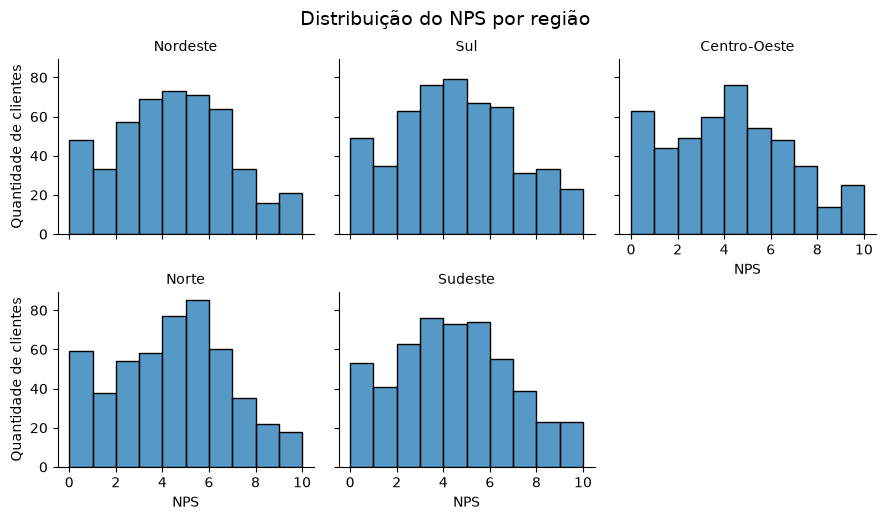

In [114]:
# Graficos de distribuição de nps por região
g = sns.displot(
    data=df,
    x="nps_score",
    col="customer_region",
    col_wrap=3,
    bins=10,
    height=2.5,
    aspect=1.2,
    common_bins=True,
    common_norm=False
)

g.set_axis_labels("NPS", "Quantidade de clientes")
g.set_titles("{col_name}")

g.fig.suptitle(
    "Distribuição do NPS por região",
    y=1.03,
    fontsize=14
)

g.savefig(
    pasta_figuras / "03_distribuicao_nps_por_regiao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [116]:
df["faixa_etaria"] = pd.cut(
    df["customer_age"],
    bins=[17, 25, 35, 45, 55, 65, 69],
    labels=[
        "18 a 25",
        "26 a 35",
        "36 a 45",
        "46 a 55",
        "56 a 65",
        "66 a 69"
    ]
)

In [117]:
#Validação do NPS por faixa etária
# A idade dos clientes será agrupada em faixas para verificar se existem diferenças relevantes no comportamento do NPS entre diferentes perfis etários.

resumo_por_idade = (
    df.groupby("faixa_etaria", observed=True)
      .agg(
          quantidade=("nps_score", "size"),
          nps_medio=("nps_score", "mean"),
          nps_mediano=("nps_score", "median"),
          desvio_padrao_nps=("nps_score", "std"),
          taxa_recompra_30d=("repeat_purchase_30d", "mean")
      )
      .reset_index()
)

resumo_por_idade["percentual_base"] = (
    resumo_por_idade["quantidade"] / len(df) * 100
)

resumo_por_idade["taxa_recompra_30d"] *= 100

resumo_por_idade = resumo_por_idade[
    [
        "faixa_etaria",
        "quantidade",
        "percentual_base",
        "nps_medio",
        "nps_mediano",
        "desvio_padrao_nps",
        "taxa_recompra_30d"
    ]
].round(2)

display(resumo_por_idade)

,faixa_etaria,quantidade,percentual_base,nps_medio,nps_mediano,desvio_padrao_nps,taxa_recompra_30d
0,18 a 25,389,15.56,4.48,4.40,2.41,9.00
1,26 a 35,465,18.60,4.56,4.50,2.55,9.89
2,36 a 45,517,20.68,4.12,4.10,2.43,6.58
3,46 a 55,468,18.72,4.41,4.50,2.60,9.40
4,56 a 65,476,19.04,4.27,4.40,2.53,7.77
5,66 a 69,185,7.40,4.64,4.50,2.52,11.89


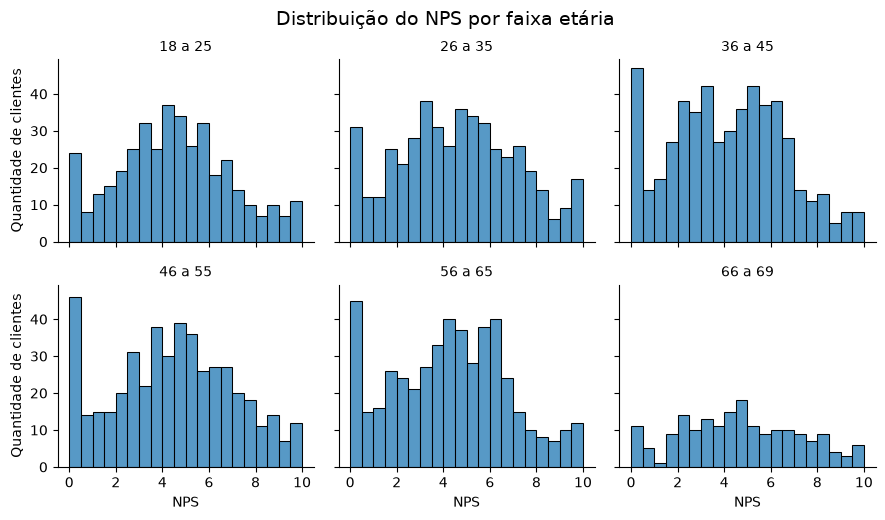

In [118]:
#Gráficos de distribuição de nps por faixa etária
g = sns.displot(
    data=df,
    x="nps_score",
    col="faixa_etaria",
    col_wrap=3,
    bins=20,
    height=2.5,
    aspect=1.2,
    common_bins=True,
    common_norm=False
)

g.set_axis_labels("NPS", "Quantidade de clientes")
g.set_titles("{col_name}")

g.fig.suptitle(
    "Distribuição do NPS por faixa etária",
    y=1.03,
    fontsize=14
)

g.savefig(
    pasta_figuras / "04_distribuicao_nps_por_faixa_etaria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Observações iniciais - Fase 1

Dados Gerais:
Apesar da proximidade entre média e mediana e da baixa assimetria geral, foi observada uma concentração específica na nota 0, que representa 6,32% dos registros. A nota 10 também apresenta uma concentração pontual, porém menor, correspondente a 1,68% da base.
O intervalo entre o primeiro e o terceiro quartis mostra que 50% das observações estão entre 2,6 e 6,1. O boxplot não identificou valores atípicos, e todas as observações permanecem dentro da escala válida de 0 a 10.
Os resultados indicam que a distribuição não deve ser interpretada apenas pela média ou pela assimetria, pois os extremos, principalmente a nota 0, apresentam comportamentos específicos que serão avaliados nas próximas análises.

Abertura por Região:
A distribuição do NPS apresenta comportamento semelhante entre as regiões, com concentração predominante nas notas intermediárias e redução da frequência nas notas mais altas. Embora existam pequenas diferenças, como um NPS médio ligeiramente menor no Centro-Oeste e maior no Sul, não foram identificadas distorções regionais relevantes nesta análise inicial.
Dessa forma, a região não será priorizada como fator explicativo neste momento, permanecendo disponível para análises complementares caso outros resultados indiquem essa necessidade.

Abertura por Idade:
As distribuições do NPS apresentam comportamento semelhante entre as faixas etárias, com concentração predominante nas notas intermediárias e presença de notas baixas em todos os grupos.
A faixa de 36 a 45 anos apresentou o menor NPS médio, de 4,12, e a menor taxa de recompra em 30 dias, de 6,58%. Em contrapartida, a faixa de 66 a 69 anos apresentou o maior NPS médio, de 4,64, e a maior taxa de recompra, de 11,89%.
Essas diferenças devem ser interpretadas com cautela, especialmente porque a faixa de 66 a 69 anos possui uma quantidade menor de observações. Além disso, as medianas, os desvios-padrão e os formatos das distribuições são semelhantes entre os grupos.
Dessa forma, não foi identificada evidência descritiva suficientemente forte para priorizar a idade como fator explicativo do NPS. A influência da idade será posteriormente complementada pela análise de correlação com os registros individuais.

In [ ]:
#Criação da base processada.
#A base original será preservada sem alterações. Nesta etapa, será gerada uma versão processada contendo a variável nps_faixa, criada para apoiar a análise exploratória do comportamento dos indicadores ao longo da escala de NPS.

from pathlib import Path

# Limites e nomes das faixas exploratórias
limites_faixas = [
    -0.01,
    0.0,
    1.0,
    2.0,
    3.0,
    4.0,
    5.0,
    6.0,
    7.0,
    8.0,
    9.0,
    9.9,
    10.0
]
nomes_faixas = [
    "0",
    "0.1 a 1.0",
    "1.1 a 2.0",
    "2.1 a 3.0",
    "3.1 a 4.0",
    "4.1 a 5.0",
    "5.1 a 6.0",
    "6.1 a 7.0",
    "7.1 a 8.0",
    "8.1 a 9.0",
    "9.1 a 9.9",
    "10"
]
# Criação da classificação exploratória
df["nps_faixa"] = pd.cut(
    df["nps_score"],
    bins=limites_faixas,
    labels=nomes_faixas,
    right=True,
    include_lowest=True,
    ordered=True
)
# Caminho do arquivo processado
caminho_saida = Path(
    "../1.data/2.processed/desafio_nps_fase_1_processed.csv"
)
# Garante que a pasta exista
caminho_saida.parent.mkdir(parents=True, exist_ok=True)
# Salva a base sem criar uma coluna adicional de índice
df.to_csv(
    caminho_saida,
    index=False,
    encoding="utf-8-sig"
)
print(f"Arquivo salvo em: {caminho_saida}")

Arquivo salvo em: ..\1.data\2.processed\desafio_nps_fase_1_processed.csv


In [39]:
# Variáveis numéricas relevantes para a análise por faixa
variaveis_resumo = [
    "customer_age",
    "customer_tenure_months",
    "order_value",
    "items_quantity",
    "discount_value",
    "payment_installments",
    "delivery_time_days",
    "delivery_delay_days",
    "freight_value",
    "delivery_attempts",
    "customer_service_contacts",
    "resolution_time_days",
    "complaints_count",
    "csat_internal_score"
]

# Resumo geral por faixa de NPS
resumo_por_faixa = (
    df.groupby("nps_faixa", observed=True)
      .agg(
          quantidade=("nps_score", "size"),
          nps_medio=("nps_score", "mean"),
          **{
              f"{coluna}_media": (coluna, "mean")
              for coluna in variaveis_resumo
          },
          taxa_recompra_30d=("repeat_purchase_30d", "mean")
      )
      .reset_index()
)

# Conversão da recompra para percentual
resumo_por_faixa["taxa_recompra_30d"] *= 100

# Arredondamento para facilitar a leitura
resumo_por_faixa = resumo_por_faixa.round(2)

display(resumo_por_faixa)

,nps_faixa,quantidade,nps_medio,customer_age_media,customer_tenure_months_media,order_value_media,items_quantity_media,discount_value_media,payment_installments_media,delivery_time_days_media,delivery_delay_days_media,freight_value_media,delivery_attempts_media,customer_service_contacts_media,resolution_time_days_media,complaints_count_media,csat_internal_score_media,taxa_recompra_30d
0,0,158,0.00,44.65,61.72,417.21,3.32,28.31,6.09,8.16,4.11,39.11,1.94,2.65,6.35,5.76,0.70,0.00
1,0.1 a 1.0,124,0.58,44.78,65.12,419.56,3.31,28.68,5.87,7.50,3.67,39.58,1.90,2.08,6.20,5.08,1.17,0.00
2,1.1 a 2.0,208,1.61,43.50,60.80,407.08,3.45,29.41,5.60,8.30,3.08,38.29,2.10,1.80,6.61,4.89,1.45,0.00
3,2.1 a 3.0,288,2.57,42.98,61.39,434.90,3.56,30.67,5.92,8.02,2.77,39.15,1.95,1.78,5.89,4.72,1.89,0.00
4,3.1 a 4.0,344,3.55,42.64,61.77,438.39,3.46,28.25,6.11,7.93,2.33,38.42,2.01,1.66,5.60,4.61,2.50,0.00
5,4.1 a 5.0,385,4.56,43.07,59.70,430.78,3.57,29.36,6.01,8.15,1.94,37.76,1.99,1.47,5.77,4.31,2.90,0.00
6,5.1 a 6.0,344,5.55,43.27,62.76,434.67,3.56,31.53,6.03,7.78,1.74,37.79,2.01,1.26,5.04,4.05,3.64,0.00
7,6.1 a 7.0,286,6.53,43.70,59.43,434.92,3.39,28.89,6.03,8.23,1.53,37.78,2.03,1.20,4.90,3.14,4.02,0.00
8,7.1 a 8.0,162,7.54,42.99,59.65,469.25,3.29,30.19,6.47,7.93,1.16,38.14,2.07,1.01,4.71,2.72,4.61,10.49
9,8.1 a 9.0,96,8.50,44.67,62.88,449.35,3.38,30.39,5.94,8.17,0.81,37.06,1.91,0.88,4.51,2.50,5.14,100.00


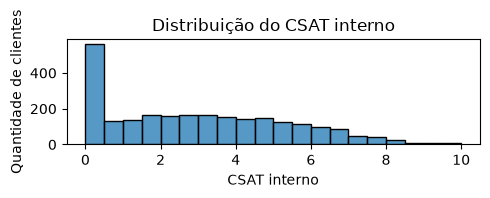

In [119]:
# Distribuição do CSAT Interno
plt.figure(figsize=(5, 2))

sns.histplot(
    data=df,
    x="csat_internal_score",
    bins=20
)

plt.title("Distribuição do CSAT interno")
plt.xlabel("CSAT interno")
plt.ylabel("Quantidade de clientes")

plt.tight_layout()

plt.savefig(
    pasta_figuras / "05_distribuicao_csat_interno.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Avaliar correlação entre NPS e CSAT
# PEarson para validar o quanto a relação se aproxima linearmente
# Spearman para validar tendência de aumento correlato entre as variáveis
correlacao_pearson = df[
    ["nps_score", "csat_internal_score"]
].corr(method="pearson").iloc[0, 1]

correlacao_spearman = df[
    ["nps_score", "csat_internal_score"]
].corr(method="spearman").iloc[0, 1]

print(f"Correlação de Pearson: {correlacao_pearson:.3f}")
print(f"Correlação de Spearman: {correlacao_spearman:.3f}")

Correlação de Pearson: 0.564
Correlação de Spearman: 0.561


In [70]:
resumo_csat_por_faixa = (
    df.groupby("nps_faixa", observed=True)
      .agg(
          quantidade=("csat_internal_score", "size"),
          csat_medio=("csat_internal_score", "mean"),
          csat_mediano=("csat_internal_score", "median"),
          csat_desvio_padrao=("csat_internal_score", "std"),
          csat_minimo=("csat_internal_score", "min"),
          csat_maximo=("csat_internal_score", "max")
      )
      .reset_index()
      .round(2)
)

display(resumo_csat_por_faixa)

,nps_faixa,quantidade,csat_medio,csat_mediano,csat_desvio_padrao,csat_minimo,csat_maximo
0,0,158,0.70,0.00,1.26,0.00,5.20
1,0.1 a 1.0,124,1.17,0.15,1.60,0.00,6.70
2,1.1 a 2.0,208,1.45,0.70,1.66,0.00,7.70
3,2.1 a 3.0,288,1.89,1.40,1.94,0.00,8.20
4,3.1 a 4.0,344,2.50,2.20,2.06,0.00,7.50
5,4.1 a 5.0,385,2.90,2.90,1.95,0.00,8.50
6,5.1 a 6.0,344,3.64,3.50,2.11,0.00,8.90
7,6.1 a 7.0,286,4.02,4.20,2.21,0.00,8.60
8,7.1 a 8.0,162,4.61,4.80,2.16,0.00,9.60
9,8.1 a 9.0,96,5.14,5.50,2.06,0.20,10.00


Principais observações - Final Fase 1

A análise por faixa revelou diferenças claras principalmente nos indicadores de atraso, atendimento e satisfação interna.

O atraso médio na entrega diminui progressivamente conforme o NPS aumenta, passando de 4,11 dias entre os clientes com NPS 0 para 0,57 dia entre aqueles com NPS 10. Comportamento semelhante foi observado na quantidade de reclamações, nos contatos com o atendimento e no tempo de resolução.

    Fatores mais  associados a notas baixas:

        maior atraso na entrega
        maior número de reclamações
        maior número de contatos com o atendimento
        maior tempo de resolução
        menor CSAT interno

O tempo total de entrega, por outro lado, permaneceu relativamente estável entre as faixas. Esse resultado sugere que o descumprimento do prazo esperado pode ser mais relevante para a satisfação do que a duração absoluta da entrega.

O CSAT interno aumentou de forma consistente ao longo das faixas, indicando forte associação positiva com o NPS. Entretanto, por também representar uma medida de satisfação, sua disponibilidade e forma de cálculo deverão ser avaliadas antes de uma eventual utilização em modelos preditivos.

A recompra em 30 dias apresentou uma mudança abrupta: foi igual a zero nas faixas ate 7.9 e igual a 100% a partir de 8,0. Apresenta uma relação determinística entre NPS e recompra, impedindo avaliar de forma independente a associação entre satisfação e recompra.
O resultado não indica um comportamento natural e precisa ser avaliado, portanto a variável não será utilizada para o estudo nesse momento.

As demais características de cliente, pedido e entrega não apresentaram, nesta visão inicial, tendência suficiente para serem consideradas fatores prioritários.

Fase 2 - Análise de correlação

A análise de correlação será utilizada para medir a direção e a intensidade da associação entre o nps_score e as demais variáveis numéricas.
Serão comparadas as correlações de Pearson e Spearman. A correlação de Pearson para avaliar principalmente relações lineares, enquanto a correlação de Spearman identificar tendências crescentes ou decrescentes, mesmo quando a relação não é perfeitamente linear.
As variáveis de identificação e as classificações criadas durante a análise da Fase 01 foram desconsideradas. A variável repeat_purchase_30d também foi excluída por apresentar uma relação determinística com o NPS.
O csat_internal_score será mantido nesta análise exploratória, mas seus resultados serão interpretados separadamente devido à ausência de informações sobre sua construção e seu momento de cálculo.

In [79]:
# Análise de correlação
variaveis_correlacao = [
    "nps_score",
    "customer_age",
    "customer_tenure_months",
    "order_value",
    "items_quantity",
    "discount_value",
    "payment_installments",
    "delivery_time_days",
    "delivery_delay_days",
    "freight_value",
    "delivery_attempts",
    "customer_service_contacts",
    "resolution_time_days",
    "complaints_count",
    "csat_internal_score"
]

# Correlação das variáveis com o NPS
correlacao_pearson = (
    df[variaveis_correlacao]
    .corr(method="pearson")["nps_score"]
    .drop("nps_score")
)
correlacao_spearman = (
    df[variaveis_correlacao]
    .corr(method="spearman")["nps_score"]
    .drop("nps_score")
)

# Consolidação dos resultados
resumo_correlacoes = pd.DataFrame({
    "correlacao_pearson": correlacao_pearson,
    "correlacao_spearman": correlacao_spearman
})

# Classificação da intensidade da correlação
def classificar_correlacao(valor):
    intensidade = abs(valor)

    if intensidade < 0.10:
        return "Muito fraca"
    elif intensidade < 0.30:
        return "Fraca"
    elif intensidade < 0.50:
        return "Moderada"
    elif intensidade < 0.70:
        return "Moderada a forte"
    else:
        return "Forte"

resumo_correlacoes["classificacao"] = (
    resumo_correlacoes["correlacao_spearman"]
    .apply(classificar_correlacao)
)

# Ordenação pela intensidade da correlação de Spearman
resumo_correlacoes["intensidade_spearman"] = (
    resumo_correlacoes["correlacao_spearman"].abs()
)

resumo_correlacoes = (
    resumo_correlacoes
    .sort_values("intensidade_spearman", ascending=False)
    .drop(columns="intensidade_spearman")
    .round(2)
)
display(resumo_correlacoes)

,correlacao_pearson,correlacao_spearman,classificacao
delivery_delay_days,-0.60,-0.59,Moderada a forte
csat_internal_score,0.56,0.56,Moderada a forte
complaints_count,-0.50,-0.49,Moderada
customer_service_contacts,-0.35,-0.34,Moderada
resolution_time_days,-0.19,-0.19,Fraca
freight_value,-0.04,-0.04,Muito fraca
order_value,0.04,0.04,Muito fraca
payment_installments,0.02,0.03,Muito fraca
delivery_attempts,0.03,0.03,Muito fraca
customer_tenure_months,-0.01,-0.01,Muito fraca


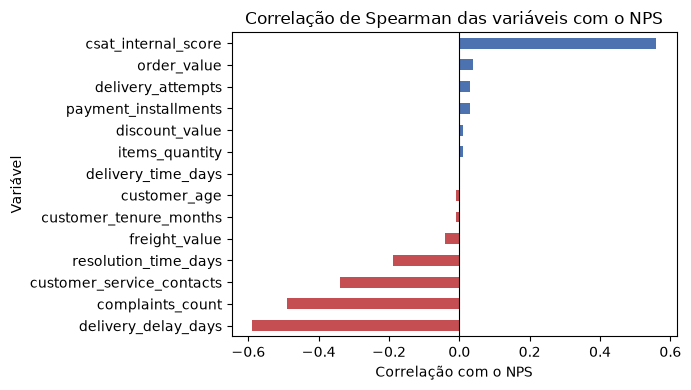

In [120]:
# Visualização dos resultados de correlação

correlacoes_grafico = (
    resumo_correlacoes["correlacao_spearman"]
    .sort_values()
)

cores = [
    "#C44E52" if valor < 0 else "#4C72B0"
    for valor in correlacoes_grafico
]

plt.figure(figsize=(7, 4))

correlacoes_grafico.plot(
    kind="barh",
    color=cores
)

plt.axvline(
    x=0,
    color="black",
    linewidth=0.8
)

plt.title("Correlação de Spearman das variáveis com o NPS")
plt.xlabel("Correlação com o NPS")
plt.ylabel("Variável")

plt.tight_layout()

plt.savefig(
    pasta_figuras / "06_correlacao_spearman_nps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Fase 2 - Resultados da análise de correlação 

A análise de correlação confirmou os padrões identificados anteriormente na comparação das faixas de NPS.

O atraso na entrega apresentou a associação operacional mais intensa com o NPS, com correlação de Spearman de -0,59. Esse resultado indica que o NPS tende a diminuir de forma consistente à medida que aumentam os dias de atraso.

A quantidade de reclamações também apresentou associação negativa relevante, com correlação de -0,49. Os contatos com o atendimento apresentaram correlação moderada de -0,34, enquanto o tempo de resolução apresentou associação negativa mais fraca, de -0,19.

O CSAT interno apresentou correlação positiva de 0,56 com o NPS. O resultado confirma que os dois indicadores se movimentam na mesma direção, mas não possuem uma relação determinística. Ainda assim, o CSAT permanecerá sob ressalva para eventual modelagem, pois sua forma e seu momento de cálculo não estão documentados.

Um resultado relevante foi a diferença entre o tempo total de entrega e o atraso. O tempo total apresentou correlação próxima de zero com o NPS, enquanto o atraso apresentou a maior associação negativa. Isso sugere que o descumprimento do prazo esperado possui maior relação com a insatisfação do que a duração absoluta da entrega.

As demais características relacionadas ao perfil do cliente, ao pedido e ao pagamento apresentaram correlações muito próximas de zero, não sendo consideradas fatores prioritários nesta etapa.

Fase 3 - Análise dos pontos de ruptura

Após identificar os fatores mais associados ao NPS, esta etapa busca aprofundar o comportamento dos principais indicadores operacionais e verificar se existem níveis a partir dos quais a satisfação apresenta mudanças mais relevantes.

Serão analisados o atraso na entrega, a quantidade de reclamações, os contatos com o atendimento e o tempo de resolução. Para cada indicador, serão observados o comportamento do NPS, o tamanho dos grupos e as variações entre níveis consecutivos, buscando identificar possíveis pontos críticos para a experiência do cliente.

O objetivo não é estabelecer relações de causalidade, mas transformar as associações encontradas anteriormente em referências operacionais que possam apoiar a tomada de decisão.

# Ruptura relacionado ao atraso

In [ ]:
resumo_por_atraso = (
    df.groupby("delivery_delay_days")
      .agg(
          quantidade=("nps_score", "size"),
          percentual_base=("nps_score", lambda x: len(x) / len(df) * 100),
          nps_medio=("nps_score", "mean"),
          nps_mediano=("nps_score", "median"),
          desvio_padrao_nps=("nps_score", "std"),
          reclamacoes_media=("complaints_count", "mean"),
          contatos_media=("customer_service_contacts", "mean"),
          resolucao_media=("resolution_time_days", "mean")
      )
      .reset_index()
      .round(2)
)

display(resumo_por_atraso)

,delivery_delay_days,quantidade,percentual_base,nps_medio,nps_mediano,desvio_padrao_nps,reclamacoes_media,contatos_media,resolucao_media
0,0,277,11.08,6.86,6.80,2.01,2.96,1.55,5.69
1,1,615,24.60,5.55,5.50,2.18,4.14,1.56,5.48
2,2,646,25.84,4.58,4.60,2.04,4.22,1.53,5.44
3,3,525,21.00,3.44,3.40,2.00,4.35,1.45,5.49
4,4,270,10.80,2.44,2.30,1.83,4.54,1.56,5.46
5,5,116,4.64,1.48,1.25,1.60,4.57,1.47,5.52
6,6,34,1.36,1.10,0.70,1.24,4.88,1.50,4.94
7,7,14,0.56,0.29,0.00,0.42,4.21,1.07,5.29
8,8,3,0.12,0.00,0.00,0.00,4.33,1.67,5.67


In [81]:
resumo_por_atraso["variacao_nps_medio"] = (
    resumo_por_atraso["nps_medio"].diff()
)

resumo_por_atraso["variacao_percentual_nps"] = (
    resumo_por_atraso["nps_medio"].pct_change() * 100
)

display(
    resumo_por_atraso[
        [
            "delivery_delay_days",
            "quantidade",
            "nps_medio",
            "nps_mediano",
            "variacao_nps_medio",
            "variacao_percentual_nps"
        ]
    ].round(2)
)

,delivery_delay_days,quantidade,nps_medio,nps_mediano,variacao_nps_medio,variacao_percentual_nps
0,0,277,6.86,6.80,NaN,NaN
1,1,615,5.55,5.50,-1.31,-19.10
2,2,646,4.58,4.60,-0.97,-17.48
3,3,525,3.44,3.40,-1.14,-24.89
4,4,270,2.44,2.30,-1.00,-29.07
5,5,116,1.48,1.25,-0.96,-39.34
6,6,34,1.10,0.70,-0.38,-25.68
7,7,14,0.29,0.00,-0.81,-73.64
8,8,3,0.00,0.00,-0.29,-100.00


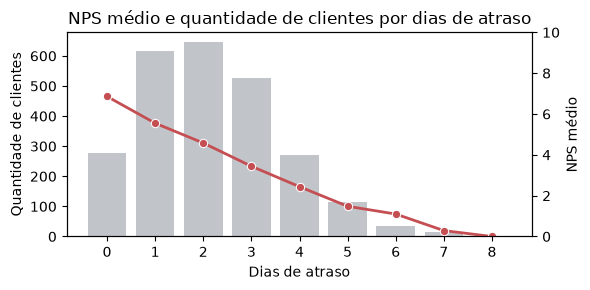

In [121]:
# Ruptura por atraso - compara o volume de clientes e o NPS médio por dias de atraso
fig, ax1 = plt.subplots(figsize=(6, 3))

sns.barplot(
    data=resumo_por_atraso,
    x="delivery_delay_days",
    y="quantidade",
    color="#BFC5CC",
    ax=ax1
)

ax1.set_xlabel("Dias de atraso")
ax1.set_ylabel("Quantidade de clientes")
ax1.tick_params(axis="y")

ax2 = ax1.twinx()

sns.lineplot(
    data=resumo_por_atraso,
    x="delivery_delay_days",
    y="nps_medio",
    marker="o",
    color="#C44E52",
    linewidth=2,
    ax=ax2
)

ax2.set_ylabel("NPS médio")
ax2.set_ylim(0, 10)

plt.title("NPS médio e quantidade de clientes por dias de atraso")
fig.tight_layout()

plt.savefig(
    pasta_figuras / "07_ruptura_atraso.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Fase 3 - Resultados de ruptura relacionado ao atraso

Não foi identificado um único ponto de ruptura abrupto. Os resultados indicam que o impacto negativo começa já no primeiro dia de atraso e se intensifica de forma contínua. Como referência operacional, atrasos a partir de três dias podem ser considerados críticos, pois estão associados a um NPS médio de 3,44 e ainda representam uma parcela relevante da base.

Os grupos com seis ou mais dias de atraso possuem poucas observações e, por isso, seus resultados devem ser interpretados com cautela.

A quantidade de contatos e o tempo médio de resolução permaneceram relativamente estáveis entre os níveis de atraso. Dessa forma, a redução do NPS parece estar diretamente associada ao descumprimento do prazo, embora uma eventual relação causal não possa ser afirmada apenas com esta análise descritiva.

# Ruptura relacionada as reclamações

In [86]:
resumo_por_reclamacoes = (
    df.groupby("complaints_count")
      .agg(
          quantidade=("nps_score", "size"),
          percentual_base=("nps_score", lambda x: len(x) / len(df) * 100),
          nps_medio=("nps_score", "mean"),
          nps_mediano=("nps_score", "median"),
          desvio_padrao_nps=("nps_score", "std"),
          atraso_medio=("delivery_delay_days", "mean"),
          contatos_media=("customer_service_contacts", "mean"),
          resolucao_media=("resolution_time_days", "mean")
      )
      .reset_index()
      .round(2)
)

display(resumo_por_reclamacoes)

,complaints_count,quantidade,percentual_base,nps_medio,nps_mediano,desvio_padrao_nps,atraso_medio,contatos_media,resolucao_media
0,0,23,0.92,8.52,8.70,1.31,0.00,0.00,5.52
1,1,122,4.88,7.77,7.60,1.31,1.02,0.25,5.25
2,2,277,11.08,6.05,6.40,2.26,1.80,0.39,5.34
3,3,507,20.28,4.91,4.90,2.28,2.19,0.87,5.52
4,4,600,24.00,4.22,4.30,2.24,2.35,1.32,5.38
5,5,444,17.76,3.65,3.70,2.14,2.38,1.90,5.57
6,6,266,10.64,3.06,3.00,1.91,2.38,2.61,5.71
7,7,169,6.76,2.81,2.60,2.16,2.41,3.09,5.66
8,8,63,2.52,2.07,2.30,1.77,2.51,3.60,5.98
9,9,16,0.64,2.49,3.25,2.13,2.12,4.25,3.69


In [87]:
resumo_por_reclamacoes["variacao_nps_medio"] = (
    resumo_por_reclamacoes["nps_medio"].diff()
)

resumo_por_reclamacoes["variacao_percentual_nps"] = (
    resumo_por_reclamacoes["nps_medio"].pct_change() * 100
)

display(
    resumo_por_reclamacoes[
        [
            "complaints_count",
            "quantidade",
            "percentual_base",
            "nps_medio",
            "nps_mediano",
            "variacao_nps_medio",
            "variacao_percentual_nps"
        ]
    ].round(2)
)

,complaints_count,quantidade,percentual_base,nps_medio,nps_mediano,variacao_nps_medio,variacao_percentual_nps
0,0,23,0.92,8.52,8.70,NaN,NaN
1,1,122,4.88,7.77,7.60,-0.75,-8.80
2,2,277,11.08,6.05,6.40,-1.72,-22.14
3,3,507,20.28,4.91,4.90,-1.14,-18.84
4,4,600,24.00,4.22,4.30,-0.69,-14.05
5,5,444,17.76,3.65,3.70,-0.57,-13.51
6,6,266,10.64,3.06,3.00,-0.59,-16.16
7,7,169,6.76,2.81,2.60,-0.25,-8.17
8,8,63,2.52,2.07,2.30,-0.74,-26.33
9,9,16,0.64,2.49,3.25,0.42,20.29


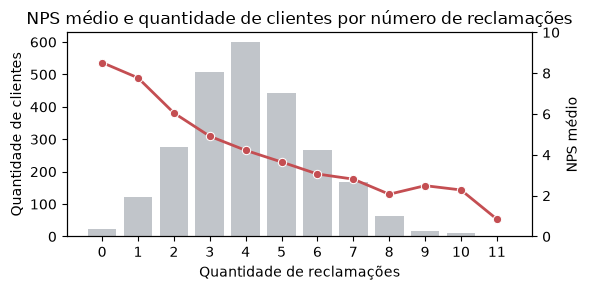

In [122]:
# Ruptura por reclamações - compara o volume de clientes e o NPS médio por quantidade de reclamações
fig, ax1 = plt.subplots(figsize=(6, 3))

sns.barplot(
    data=resumo_por_reclamacoes,
    x="complaints_count",
    y="quantidade",
    color="#BFC5CC",
    ax=ax1
)

ax1.set_xlabel("Quantidade de reclamações")
ax1.set_ylabel("Quantidade de clientes")

ax2 = ax1.twinx()

sns.lineplot(
    data=resumo_por_reclamacoes,
    x="complaints_count",
    y="nps_medio",
    marker="o",
    color="#C44E52",
    linewidth=2,
    ax=ax2
)

ax2.set_ylabel("NPS médio")
ax2.set_ylim(0, 10)

plt.title("NPS médio e quantidade de clientes por número de reclamações")
fig.tight_layout()

plt.savefig(
    pasta_figuras / "08_ruptura_reclamacoes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Ruptura relacionada aos contatos com atendimento

In [89]:
resumo_por_contatos = (
    df.groupby("customer_service_contacts")
      .agg(
          quantidade=("nps_score", "size"),
          percentual_base=("nps_score", lambda x: len(x) / len(df) * 100),
          nps_medio=("nps_score", "mean"),
          nps_mediano=("nps_score", "median"),
          desvio_padrao_nps=("nps_score", "std"),
          atraso_medio=("delivery_delay_days", "mean"),
          reclamacoes_media=("complaints_count", "mean"),
          resolucao_media=("resolution_time_days", "mean")
      )
      .reset_index()
)

# Variação do NPS entre níveis consecutivos
resumo_por_contatos["variacao_nps_medio"] = (
    resumo_por_contatos["nps_medio"].diff()
)

resumo_por_contatos["variacao_percentual_nps"] = (
    resumo_por_contatos["nps_medio"].pct_change() * 100
)

resumo_por_contatos = resumo_por_contatos.round(2)

display(resumo_por_contatos)

,customer_service_contacts,quantidade,percentual_base,nps_medio,nps_mediano,desvio_padrao_nps,atraso_medio,reclamacoes_media,resolucao_media,variacao_nps_medio,variacao_percentual_nps
0,0,554,22.16,5.54,5.50,2.40,2.19,2.51,5.53,NaN,NaN
1,1,816,32.64,4.66,4.70,2.43,2.26,3.57,5.38,-0.89,-15.99
2,2,640,25.60,4.12,4.10,2.31,2.14,4.65,5.36,-0.54,-11.61
3,3,314,12.56,3.20,2.90,2.27,2.12,5.78,5.83,-0.91,-22.22
4,4,132,5.28,2.65,2.60,2.17,2.12,7.02,5.97,-0.55,-17.09
5,5,34,1.36,2.24,2.45,1.96,2.24,7.65,4.38,-0.42,-15.68
6,6,7,0.28,0.74,0.00,1.75,2.43,9.14,6.71,-1.50,-66.81
7,7,3,0.12,1.20,0.40,1.74,1.00,10.00,3.33,0.46,61.54


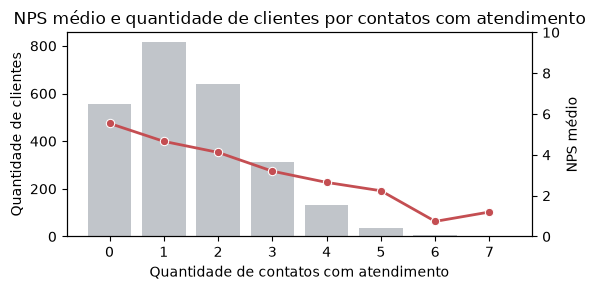

In [123]:
# Ruptura por contatos - compara o volume de clientes e o NPS médio por quantidade de contatos com atendimento
fig, ax1 = plt.subplots(figsize=(6, 3))

sns.barplot(
    data=resumo_por_contatos,
    x="customer_service_contacts",
    y="quantidade",
    color="#BFC5CC",
    ax=ax1
)

ax1.set_xlabel("Quantidade de contatos com atendimento")
ax1.set_ylabel("Quantidade de clientes")

ax2 = ax1.twinx()

sns.lineplot(
    data=resumo_por_contatos,
    x="customer_service_contacts",
    y="nps_medio",
    marker="o",
    color="#C44E52",
    linewidth=2,
    ax=ax2
)

ax2.set_ylabel("NPS médio")
ax2.set_ylim(0, 10)

plt.title("NPS médio e quantidade de clientes por contatos com atendimento")

fig.tight_layout()

plt.savefig(
    pasta_figuras / "09_ruptura_contatos_atendimento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Fase 3 - Resultados de ruptura relacionado aos contatos com atendimento

Não foi identificado um ponto de ruptura isolado, pois a deterioração começa já no primeiro contato. Entretanto, três contatos podem ser considerados um nível operacional crítico, por estarem associados a um NPS médio de 3,20.

A quantidade média de reclamações aumentou de forma consistente junto com o número de contatos. Por outro lado, o atraso e o tempo de resolução permaneceram relativamente estáveis. Esse resultado indica que múltiplos contatos podem representar principalmente a recorrência de problemas ou reclamações, e não necessariamente uma causa isolada da insatisfação.

Os resultados relativos a seis e sete contatos devem ser interpretados com cautela, pois esses grupos possuem somente sete e três clientes, respectivamente.

# Ruptura relacionado ao tempo de resolução

In [92]:
resumo_por_resolucao = (
    df.groupby("resolution_time_days")
      .agg(
          quantidade=("nps_score", "size"),
          percentual_base=("nps_score", lambda x: len(x) / len(df) * 100),
          nps_medio=("nps_score", "mean"),
          nps_mediano=("nps_score", "median"),
          desvio_padrao_nps=("nps_score", "std"),
          atraso_medio=("delivery_delay_days", "mean"),
          reclamacoes_media=("complaints_count", "mean"),
          contatos_media=("customer_service_contacts", "mean")
      )
      .reset_index()
)

resumo_por_resolucao["variacao_nps_medio"] = (
    resumo_por_resolucao["nps_medio"].diff()
)

resumo_por_resolucao["variacao_percentual_nps"] = (
    resumo_por_resolucao["nps_medio"].pct_change() * 100
)

resumo_por_resolucao = resumo_por_resolucao.round(2)

display(resumo_por_resolucao)

,resolution_time_days,quantidade,percentual_base,nps_medio,nps_mediano,desvio_padrao_nps,atraso_medio,reclamacoes_media,contatos_media,variacao_nps_medio,variacao_percentual_nps
0,0,208,8.32,5.32,5.45,2.50,2.25,4.18,1.56,NaN,NaN
1,1,192,7.68,5.00,5.00,2.59,2.18,4.20,1.55,-0.32,-5.94
2,2,229,9.16,4.82,5.00,2.45,2.19,3.90,1.39,-0.19,-3.72
3,3,237,9.48,4.63,4.60,2.66,2.20,4.19,1.54,-0.19,-3.94
4,4,206,8.24,4.44,4.30,2.45,2.13,4.27,1.62,-0.19,-4.01
5,5,176,7.04,4.42,4.45,2.34,2.24,4.02,1.48,-0.02,-0.43
6,6,197,7.88,4.32,4.50,2.56,2.25,3.97,1.38,-0.10,-2.24
7,7,213,8.52,4.26,4.40,2.46,2.21,4.18,1.41,-0.06,-1.48
8,8,227,9.08,3.97,3.80,2.38,2.22,4.14,1.47,-0.29,-6.92
9,9,204,8.16,4.05,4.10,2.32,2.04,4.32,1.62,0.08,2.02


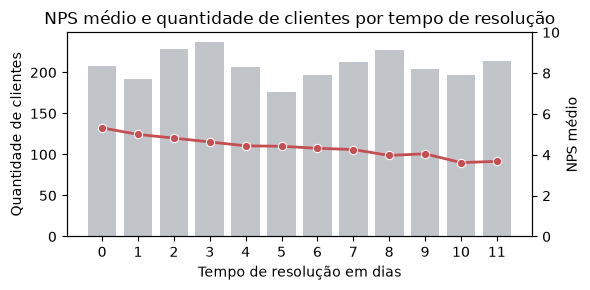

In [124]:
# Ruptura por tempo de resolução - compara o volume de clientes e o NPS médio por dias necessários para resolução
fig, ax1 = plt.subplots(figsize=(6, 3))

sns.barplot(
    data=resumo_por_resolucao,
    x="resolution_time_days",
    y="quantidade",
    color="#BFC5CC",
    ax=ax1
)

ax1.set_xlabel("Tempo de resolução em dias")
ax1.set_ylabel("Quantidade de clientes")

ax2 = ax1.twinx()

sns.lineplot(
    data=resumo_por_resolucao,
    x="resolution_time_days",
    y="nps_medio",
    marker="o",
    color="#C44E52",
    linewidth=2,
    ax=ax2
)

ax2.set_ylabel("NPS médio")
ax2.set_ylim(0, 10)

plt.title("NPS médio e quantidade de clientes por tempo de resolução")

fig.tight_layout()

plt.savefig(
    pasta_figuras / "10_ruptura_tempo_resolucao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Fase3 - Resultado de ruptura relacionado ao tempo de resolução

Apesar da tendência negativa, não foi identificado um ponto de ruptura claro. As diferenças entre prazos consecutivos foram relativamente pequenas e o comportamento apresentou algumas oscilações.
Os indicadores de atraso, reclamações e contatos também permaneceram relativamente estáveis entre os diferentes tempos de resolução. Isso indica que o prazo de resolução possui associação própria, porém mais fraca, com a satisfação.
Dessa forma, o tempo de resolução será tratado como um fator secundário. Prazos maiores estão associados a menor NPS, mas os dados não sustentam a definição de um limite operacional crítico específico.

In [96]:
variaveis_operacionais = [
    "delivery_delay_days",
    "complaints_count",
    "customer_service_contacts",
    "resolution_time_days"
]

matriz_operacional = df[variaveis_operacionais].corr(
    method="spearman"
).round(2)

display(matriz_operacional)

,delivery_delay_days,complaints_count,customer_service_contacts,resolution_time_days
delivery_delay_days,1.00,0.19,-0.02,-0.01
complaints_count,0.19,1.00,0.74,0.02
customer_service_contacts,-0.02,0.74,1.00,0.02
resolution_time_days,-0.01,0.02,0.02,1.00


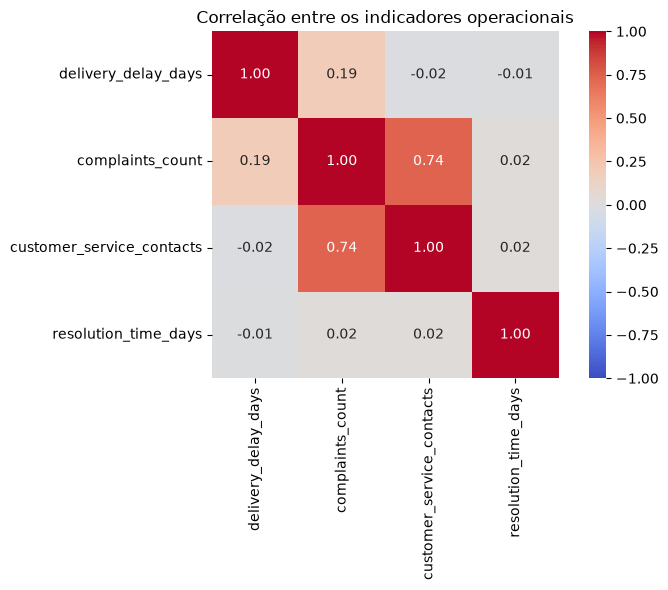

In [125]:
# Matriz de correlação operacional - identifica possíveis sobreposições entre os principais indicadores associados ao NPS
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_operacional,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlação entre os indicadores operacionais")
plt.tight_layout()

plt.savefig(
    pasta_figuras / "11_correlacao_indicadores_operacionais.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Fase 3 - Relação entre os indicadores operacionais

A matriz de correlação mostrou uma forte associação entre a quantidade de reclamações e o número de contatos com o atendimento (0,74). Esse resultado indica que os dois indicadores representam aspectos bastante relacionados da jornada, sugerindo que a necessidade de múltiplos contatos pode estar associada a recorrência de problemas ou reclamações.

O atraso na entrega apresentou baixa associação com os demais indicadores operacionais, incluindo correlação de apenas 0,19 com reclamações e praticamente nenhuma relação com contatos ou tempo de resolução. Isso reforça que o atraso representa uma dimensão própria da experiência e não apenas uma consequência dos problemas de atendimento.

O tempo de resolução também apresentou correlações próximas de zero com os demais indicadores, indicando baixa sobreposição. Entretanto, sua associação individual com o NPS já havia se mostrado mais fraca.

Dessa forma, os resultados sugerem três dimensões principais da experiência: o cumprimento do prazo de entrega, a recorrência de problemas e contatos com atendimento e, de forma secundária, o tempo necessário para resolução.

Fase 4 - Classificação oficial do NPS
Após explorar o NPS em sua escala contínua e investigar os principais fatores associados a satisfação, os clientes serão classificados conforme as categorias oficiais da metodologia NPS:

Detratores: notas de 0 a 6;
Passivos: notas de 7 a 8;
Promotores: notas de 9 a 10.

Como a base contém notas decimais, os limites foram adaptados para preservar a lógica da metodologia: notas até 6 serão classificadas como detratoras, notas acima de 6 e até 8 como passivas e notas acima de 8 como promotoras.

A nova classificação será adicionada à base processada antes das análises desta etapa, garantindo que os resultados seguintes utilizem uma estrutura padronizada e reproduzível.

In [98]:
#Criar a classificação e atualizar a base processada
from pathlib import Path
import pandas as pd

# Classificação oficial adaptada para as notas decimais da base
def classificar_nps(nota):
    if nota <= 6:
        return "Detrator"
    elif nota <= 8:
        return "Passivo"
    else:
        return "Promotor"

# Criação da coluna de classificação
df["nps_classificacao"] = (
    df["nps_score"]
    .apply(classificar_nps)
)
# Definição da ordem das categorias
ordem_classificacao = [
    "Detrator",
    "Passivo",
    "Promotor"
]

df["nps_classificacao"] = pd.Categorical(
    df["nps_classificacao"],
    categories=ordem_classificacao,
    ordered=True
)

# Validação da classificação
print(
    "Registros não classificados:",
    df["nps_classificacao"].isna().sum()
)

print(
    "Total de registros:",
    len(df)
)

display(
    df["nps_classificacao"]
    .value_counts(sort=False)
    .rename_axis("classificacao")
    .reset_index(name="quantidade")
)

# Caminho da base processada
caminho_base_processada = Path(
    "../1.data/2.processed/desafio_nps_fase_1_processed.csv"
)

# Exportação da base processada atualizada
df.to_csv(
    caminho_base_processada,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Base processada atualizada em: "
    f"{caminho_base_processada}"
)
print(f"Dimensão final da base: {df.shape}")

Registros não classificados: 0
Total de registros: 2500


,classificacao,quantidade
0,Detrator,1851
1,Passivo,448
2,Promotor,201


Base processada atualizada em: ..\1.data\2.processed\desafio_nps_fase_1_processed.csv
Dimensão final da base: (2500, 22)


In [102]:
resumo_classificacao_nps = (
    df.groupby(
        "nps_classificacao",
        observed=True
    )
    .agg(
        quantidade=("nps_score", "size"),
        nps_medio=("nps_score", "mean"),

        # Perfil do cliente
        idade_media=("customer_age", "mean"),
        tempo_relacionamento_medio=(
            "customer_tenure_months",
            "mean"
        ),

        # Características do pedido
        valor_pedido_medio=("order_value", "mean"),
        itens_media=("items_quantity", "mean"),

        # Logística
        tempo_entrega_medio=("delivery_time_days", "mean"),
        atraso_medio=("delivery_delay_days", "mean"),
        tentativas_entrega_media=("delivery_attempts", "mean"),

        # Atendimento
        reclamacoes_media=("complaints_count", "mean"),
        contatos_media=("customer_service_contacts", "mean"),
        resolucao_media=("resolution_time_days", "mean"),

        # Indicador complementar de satisfação
        csat_medio=("csat_internal_score", "mean")
    )
    .reset_index()
)

# Participação de cada grupo na base
resumo_classificacao_nps["percentual_base"] = (
    resumo_classificacao_nps["quantidade"] / len(df) * 100
)

# Organização das colunas
resumo_classificacao_nps = resumo_classificacao_nps[
    [
        "nps_classificacao",
        "quantidade",
        "percentual_base",
        "nps_medio",
        "idade_media",
        "tempo_relacionamento_medio",
        "valor_pedido_medio",
        "itens_media",
        "tempo_entrega_medio",
        "atraso_medio",
        "tentativas_entrega_media",
        "reclamacoes_media",
        "contatos_media",
        "resolucao_media",
        "csat_medio"
    ]
].round(2)

display(resumo_classificacao_nps)

,nps_classificacao,quantidade,percentual_base,nps_medio,idade_media,tempo_relacionamento_medio,valor_pedido_medio,itens_media,tempo_entrega_medio,atraso_medio,tentativas_entrega_media,reclamacoes_media,contatos_media,resolucao_media,csat_medio
0,Detrator,1851,74.04,3.26,43.31,61.58,428.99,3.49,8.00,2.53,1.99,4.62,1.69,5.79,2.34
1,Passivo,448,17.92,6.89,43.45,59.51,447.33,3.35,8.12,1.40,2.04,2.99,1.13,4.83,4.23
2,Promotor,201,8.04,9.10,44.08,63.04,453.69,3.51,8.04,0.76,2.03,2.39,0.78,4.10,5.60


Fase 5 - Exportação dos resultados da EDA

As principais tabelas geradas durante a análise exploratória serão exportadas para a pasta de resultados.
Esses arquivos registram as evidências utilizadas nas conclusões do trabalho e poderão ser reutilizados na documentação, na apresentação executiva e nas próximas etapas do projeto.

In [ ]:
from pathlib import Path

# Pasta destinada às tabelas geradas pela EDA
pasta_tabelas = Path("../5.outputs/2.tables")
pasta_tabelas.mkdir(parents=True, exist_ok=True)

# Tabelas que serão exportadas
tabelas_exportacao = {
    "resumo_geral_por_faixa_nps.csv":
        resumo_por_faixa,

    "distribuicao_classificacao_nps.csv":
        distribuicao_nps,

    "resumo_classificacao_nps.csv":
        resumo_classificacao_nps,

    "correlacoes_variaveis_com_nps.csv":
        resumo_correlacoes,

    "resumo_pontos_ruptura_atraso.csv":
        resumo_por_atraso,

    "resumo_pontos_ruptura_reclamacoes.csv":
        resumo_por_reclamacoes,

    "resumo_pontos_ruptura_contatos.csv":
        resumo_por_contatos,

    "resumo_pontos_ruptura_resolucao.csv":
        resumo_por_resolucao,

    "matriz_correlacao_operacional.csv":
        matriz_operacional
}

# Exportação dos arquivos
for nome_arquivo, tabela in tabelas_exportacao.items():
    caminho_arquivo = pasta_tabelas / nome_arquivo

    tabela.to_csv(
        caminho_arquivo,
        index=True if nome_arquivo == "matriz_correlacao_operacional.csv"
        else False,
        encoding="utf-8-sig"
    )

    print(f"Arquivo exportado: {caminho_arquivo}")

Arquivo exportado: ..\5.outputs\2.tables\resumo_geral_por_faixa_nps.csv
Arquivo exportado: ..\5.outputs\2.tables\distribuicao_classificacao_nps.csv
Arquivo exportado: ..\5.outputs\2.tables\resumo_classificacao_nps.csv
Arquivo exportado: ..\5.outputs\2.tables\correlacoes_variaveis_com_nps.csv
Arquivo exportado: ..\5.outputs\2.tables\resumo_pontos_ruptura_atraso.csv
Arquivo exportado: ..\5.outputs\2.tables\resumo_pontos_ruptura_reclamacoes.csv
Arquivo exportado: ..\5.outputs\2.tables\resumo_pontos_ruptura_contatos.csv
Arquivo exportado: ..\5.outputs\2.tables\resumo_pontos_ruptura_resolucao.csv
Arquivo exportado: ..\5.outputs\2.tables\matriz_correlacao_operacional.csv
